# 06 — CNN Models & Training

Phase 2 asks whether a small convolutional neural network (CNN), which learns its own filters from the images, does
better than Phase 1's classical models on handcrafted features. This notebook builds two CNNs, trains them with early
stopping, and chooses the final one **on the validation set**.

- Data: the same fixed split as Phase 1 (54k train / 6k val), from `load_splits()`. Pixels are already in [0, 1].
- The CNNs learn only from the 54k training images. Validation decides when to stop and which CNN wins (D-035).
- This notebook never reads the test set.

Saved results are reused: if a CNN's `results/metrics/{name}_images_val.json` exists, it is not retrained, so
**Restart & Run All** only redraws the tables and curves (D-038).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import torch
from IPython.display import display

from src import config
from src.cnn import CNN2, CNN3, count_params, make_loaders, train_cnn
from src.utils import save_fig, set_seed

set_seed()
MODELS = {"cnn2": CNN2, "cnn3": CNN3}
print("torch", torch.__version__, "| threads", config.N_JOBS)

torch 2.15.0 | threads 4


## 1. Data loaders

A CNN expects images with a **channel** dimension: (N, 28, 28) becomes (N, 1, 28, 28), where 1 means grayscale.
The training loader serves shuffled mini-batches of 64 images (about 844 per epoch); the shuffle uses a fixed seed,
so the batch order is the same on every run.

In [2]:
loaders = make_loaders()
X_batch, y_batch = next(iter(loaders["train"]))
print("train images:", len(loaders["train"].dataset), "| val images:", len(loaders["val"].dataset))
print("one batch:", tuple(X_batch.shape), X_batch.dtype, "| labels:", tuple(y_batch.shape), y_batch.dtype)
print("pixel range:", float(X_batch.min()), "to", float(X_batch.max()))

val_indices.npy MD5: 54ff6b78b27109cdfc3ebe7204040a07


train images: 54000 | val images: 6000
one batch: (64, 1, 28, 28) torch.float32 | labels: (64,) torch.int64
pixel range: 0.0 to 1.0


## 2. Architecture

Each **conv block** is a 3×3 convolution (padding 1 keeps the size), a ReLU and a 2×2 max pooling (halves height and
width). A convolution slides small learned filters over the image; each filter produces a **feature map** showing where
its pattern (an edge, a collar corner, a stripe) appears. After the blocks, the maps are flattened and two dense layers
turn them into 10 class scores; dropout (0.5) sits before the last layer.

Below, one batch goes through CNN2 layer by layer.

In [3]:
x = X_batch
rows = []
for layer in CNN2():
    x = layer(x)
    rows.append({"layer": layer.__class__.__name__, "output shape": tuple(x.shape[1:]),
                 "parameters": sum(p.numel() for p in layer.parameters())})
display(pd.DataFrame(rows))

,layer,output shape,parameters
0,Conv2d,"(32, 28, 28)",320
1,ReLU,"(32, 28, 28)",0
2,MaxPool2d,"(32, 14, 14)",0
3,Conv2d,"(64, 14, 14)",18496
4,ReLU,"(64, 14, 14)",0
5,MaxPool2d,"(64, 7, 7)",0
6,Flatten,"(3136,)",0
7,Linear,"(128,)",401536
8,ReLU,"(128,)",0
9,Dropout,"(128,)",0


**Counting parameters.** A conv layer has (kernel height × kernel width × input channels + 1 bias) × filters weights;
a dense layer has (inputs + 1) × outputs. For CNN2: (3·3·1+1)·32 = 320, (3·3·32+1)·64 = 18,496,
(3136+1)·128 = 401,536, (128+1)·10 = 1,290, total **421,642**.

CNN3 adds a third block (64→128 filters). Its extra pooling shrinks the maps to 128×3×3 = 1,152 values, so its big
dense layer is much smaller and CNN3 has **fewer** parameters (241,546) despite being deeper.

In [4]:
counts = {name: count_params(make()) for name, make in MODELS.items()}
print(counts)
assert counts == {"cnn2": 421_642, "cnn3": 241_546}

{'cnn2': 421642, 'cnn3': 241546}


## 3. Training with early stopping

Settings (D-034): Adam, learning rate 0.001, cross-entropy loss, batch size 64, at most 30 epochs.
One **epoch** is one pass over all 54k training images. After each epoch the model is scored on the 6k validation
images with dropout off. **Early stopping** keeps the weights with the lowest validation loss and stops once 5 epochs
pass without a new lowest; those best weights are then put back.

Each run is seeded and runs on CPU with deterministic algorithms, so it gives the same numbers every time (D-036).

⏱ Training both CNNs on an Apple M3 CPU: **~15–25 min** if the val JSONs are missing; ~0 s otherwise.

In [5]:
val_results = {}
for name, make in MODELS.items():
    path = config.METRICS_DIR / f"{name}_images_val.json"
    if not path.exists():
        train_cnn(name, make)  # seeds, builds the model and fresh loaders itself (D-041)
    val_results[name] = json.loads(path.read_text())
    r = val_results[name]
    print(f"{name}: best epoch {r['best_epoch']} of {r['epochs_run']} | val acc {r['best_val_acc']:.4f} "
          f"| val macro F1 {r['val_macro_f1']:.4f} | {r['train_time_s']:.0f} s")

val_indices.npy MD5: 54ff6b78b27109cdfc3ebe7204040a07


cnn2 epoch  1: train loss 0.6078 acc 0.7790 | val loss 0.3462 acc 0.8728 | 15.0s


cnn2 epoch  2: train loss 0.3938 acc 0.8574 | val loss 0.2827 acc 0.8943 | 13.7s


cnn2 epoch  3: train loss 0.3423 acc 0.8772 | val loss 0.2571 acc 0.9030 | 15.0s


cnn2 epoch  4: train loss 0.3064 acc 0.8897 | val loss 0.2447 acc 0.9133 | 14.3s


cnn2 epoch  5: train loss 0.2777 acc 0.8986 | val loss 0.2245 acc 0.9135 | 14.6s


... (25 outputs left out)

cnn3 epoch 15: train loss 0.1445 acc 0.9444 | val loss 0.1991 acc 0.9333 | 32.4s


cnn3 epoch 16: train loss 0.1367 acc 0.9484 | val loss 0.2100 acc 0.9278 | 24.8s


cnn3 epoch 17: train loss 0.1270 acc 0.9511 | val loss 0.2075 acc 0.9310 | 27.0s
early stop: no lower val loss for 5 epochs


saved models/cnn3_images_best.pt
saved results/training/cnn3_images_history.csv
saved results/metrics/cnn3_images_val.json
cnn3_images: best epoch 12 of 17, val acc 0.9308, val macro F1 0.9308
cnn3: best epoch 12 of 17 | val acc 0.9308 | val macro F1 0.9308 | 416 s


## 4. Training curves

Training loss and accuracy are averaged over the epoch with dropout **on**; validation is scored with dropout **off**.
That is why validation can look better than training early on. The dashed line marks the epoch whose weights were kept.

saved results/figures/cnn_training_curves.png


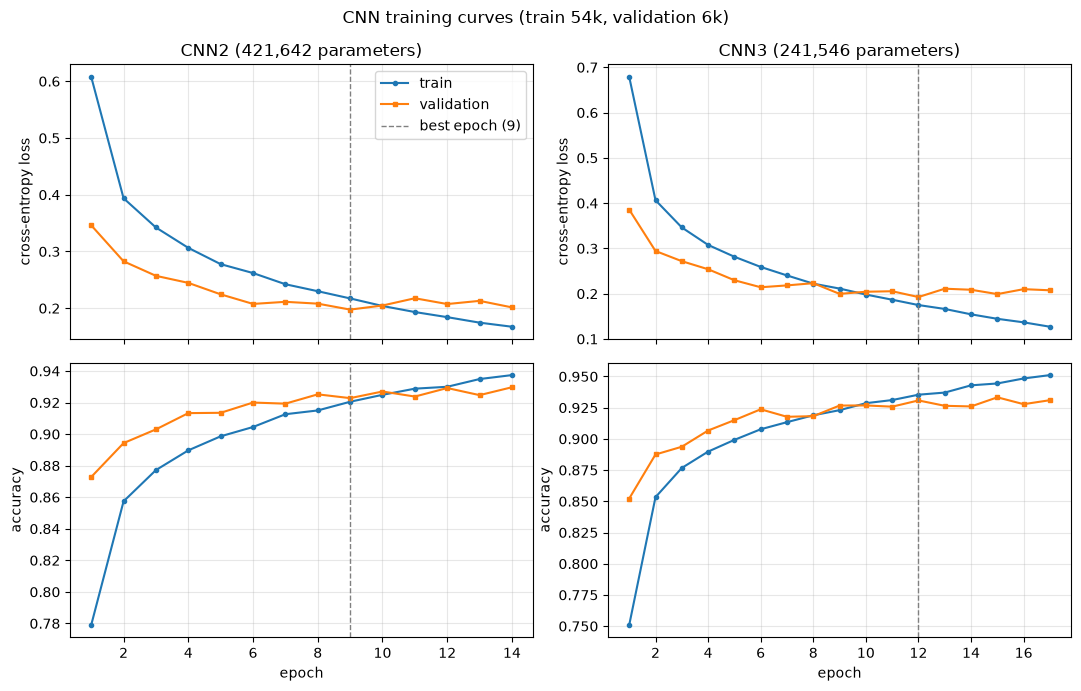

In [6]:
history = {name: pd.read_csv(config.TRAINING_DIR / f"{name}_images_history.csv") for name in MODELS}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex="col")
for col, name in enumerate(MODELS):
    h, best = history[name], val_results[name]["best_epoch"]
    for row, metric in enumerate(["loss", "acc"]):
        ax = axes[row, col]
        ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
        ax.plot(h["epoch"], h[f"val_{metric}"], marker="s", ms=3, label="validation")
        ax.axvline(best, color="gray", linestyle="--", linewidth=1, label=f"best epoch ({best})")
        ax.set_ylabel("cross-entropy loss" if metric == "loss" else "accuracy")
        ax.grid(True, alpha=0.3)
    axes[0, col].set_title(f"{name.upper()} ({counts[name]:,} parameters)")
    axes[1, col].set_xlabel("epoch")
    axes[1, col].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0, 0].legend()
fig.suptitle("CNN training curves (train 54k, validation 6k)")
fig.tight_layout()
save_fig(fig, "cnn_training_curves")
plt.show()

## 5. Model choice on validation

The final CNN is the one with the higher validation accuracy; on a tie, the one with fewer parameters (D-035).
The **train–val gap** (training accuracy at the best epoch minus validation accuracy) shows how much each model
overfits. No test data is used here.

In [7]:
table = pd.DataFrame([{
    "model": name, "parameters": r["param_count"], "best_epoch": r["best_epoch"], "epochs_run": r["epochs_run"],
    "val_acc": r["best_val_acc"], "val_macro_f1": r["val_macro_f1"], "val_loss": r["best_val_loss"],
    "train_acc_at_best": r["train_acc_at_best"], "train_val_gap": round(r["train_acc_at_best"] - r["best_val_acc"], 4),
    "train_time_s": r["train_time_s"],
} for name, r in val_results.items()]).set_index("model")
display(table)

final_cnn = max(val_results, key=lambda n: (val_results[n]["best_val_acc"], -val_results[n]["param_count"]))
print("final CNN (chosen on validation):", final_cnn)

,parameters,best_epoch,epochs_run,val_acc,val_macro_f1,val_loss,train_acc_at_best,train_val_gap,train_time_s
model,,,,,,,,,
cnn2,421642,9,14,0.9228,0.9223,0.1976,0.9205,-0.0023,198.22
cnn3,241546,12,17,0.9308,0.9308,0.1926,0.9354,0.0046,416.13


final CNN (chosen on validation): cnn3


## 6. Findings

| | CNN2 | CNN3 |
|---|---|---|
| Parameters | 421,642 | 241,546 |
| Best epoch / epochs run | 9 / 14 | 12 / 17 |
| Best val loss | 0.1976 | 0.1926 |
| Val accuracy | 0.9228 | **0.9308** |
| Val macro F1 | 0.9223 | 0.9308 |
| Train accuracy at best epoch | 0.9205 | 0.9354 |
| Training time (CPU, 4 threads) | 198 s | 416 s |

- **Both CNNs beat every Phase 1 model on validation.** The best classical model, `rbf_svm_hog`, scored 0.9157 on the
  same 6k validation images (D-029). Whether this holds on the test set is measured once, in the next step (RQ5).
- **Final CNN: CNN3**, by the rule fixed before training (higher val accuracy; D-035, D-040).
- **The depth comparison is not conclusive (RQ7).** CNN3 is 0.8 points ahead (48 of 6,000 images), but an earlier
  CNN2 run that differed only in the order of its training batches reached 0.9320 (D-041). Run-to-run variation is
  therefore about as large as the gap, so this notebook does not show that a third block helps. What it does show:
  CNN3 matches or beats CNN2 with **43% fewer parameters**, at the cost of slower epochs (the extra convolution).
- **Early stopping watches validation loss, not accuracy.** CNN2's lowest val loss came at epoch 9; its val accuracy
  kept creeping up to 0.9297 by epoch 14 while the loss stayed above 0.1976. Loss also measures how *confident* the
  correct answers are, so it starts rising (overconfident wrong answers) before accuracy stops improving.
- **Overfitting is visible after the best epoch.** CNN3's training loss keeps falling (0.175 → 0.127) while validation
  loss rises (0.193 → 0.208): the network starts memorising training images. Early stopping restored the epoch-12 weights.
- **Small train–val gap.** At the best epoch, training accuracy (measured with dropout on) is within about 0.5 points
  of validation accuracy, so dropout keeps overfitting small.
- Early on, validation accuracy is above training accuracy: training accuracy is averaged over an epoch while the
  weights are still improving, and dropout is on during training but off during validation.
- Epoch times vary between runs on the same laptop (CNN3: ~17–30 s per epoch), so training times are approximate.
